## AUTOENCODER : FOR FRAUD DETECTION
in this example we make as a **semi-supervised** anomaly detection task, where the model trains exclusively on normal instances without using target labels (Y), reserving the true ground truth strictly for final evaluation.

In [96]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration des graphiques
plt.rcParams['figure.figsize'] = (12, 9)
plt.rcParams['font.size'] = 10

# Prétraitement et évaluation (Scikit-Learn)
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, classification_report, confusion_matrix

# Deep Learning (Keras / Core TensorFlow)
import tensorflow as tf
from keras import Model, Sequential
from keras.layers import Dense, Input
from keras.optimizers import Adam
from tensorflow.keras.losses import mae
from tensorflow.keras.metrics import Mean
from keras.callbacks import ModelCheckpoint, EarlyStopping


In [61]:
!ls /kaggle/input/card-transdata

card_transdata.csv


## Loading data from kaggle datasets

In [62]:
# Download latest version
import kagglehub

# Download latest version
path = kagglehub.dataset_download("elakiyasekar/card-transdata")


print("Path to dataset files:", path)


Using Colab cache for faster access to the 'card-transdata' dataset.
Path to dataset files: /kaggle/input/card-transdata


In [63]:
df = pd.read_csv('/kaggle/input/card-transdata/card_transdata.csv')
df.head()


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  float64
 6   online_order                    1000000 non-null  float64
 7   fraud                           1000000 non-null  float64
dtypes: float64(8)
memory usage: 61.0 MB


In [65]:
df.fraud.value_counts(normalize=True) * 100

,proportion
fraud,
0.0,91.2597
1.0,8.7403


There is 8.74 of fraud samples

## basics stats

In [66]:
df.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,26.628792,5.036519,1.824182,0.881536,0.350399,0.100608,0.650552,0.087403
std,65.390784,25.843093,2.799589,0.323157,0.477095,0.300809,0.476796,0.282425
min,0.004874,0.000118,0.004399,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.878008,0.296671,0.475673,1.000000,0.000000,0.000000,0.000000,0.000000
50%,9.967760,0.998650,0.997717,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.743985,3.355748,2.096370,1.000000,1.000000,0.000000,1.000000,0.000000
max,10632.723672,11851.104565,267.802942,1.000000,1.000000,1.000000,1.000000,1.000000


## categorical vs numeric features

In [67]:
cat_ft = [f for f in df.columns if len(df[f].unique()) <=2 ]
num_ft = [f for f in df.columns if f not in cat_ft]

In [68]:
print(f"categorical ft:{cat_ft}")
print(f"Numeric ft:{num_ft}")

categorical ft:['repeat_retailer', 'used_chip', 'used_pin_number', 'online_order', 'fraud']
Numeric ft:['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price']


# autoencoders
- The dataset is heavily imbalanced
- The autoencoders only require instances of genuine samples for training
- The fraud samples will be used for testing



## but before train a model, we make some data exploration

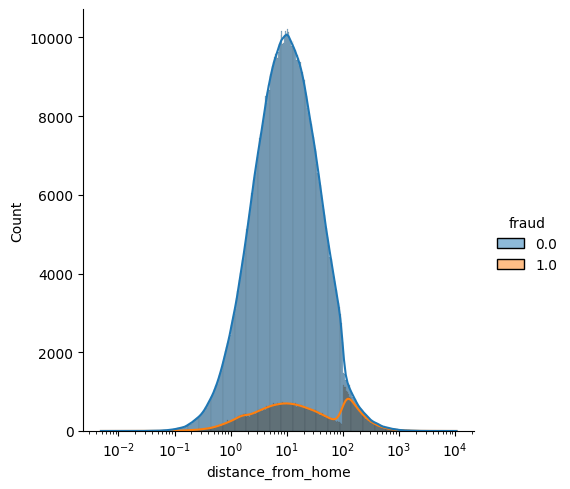

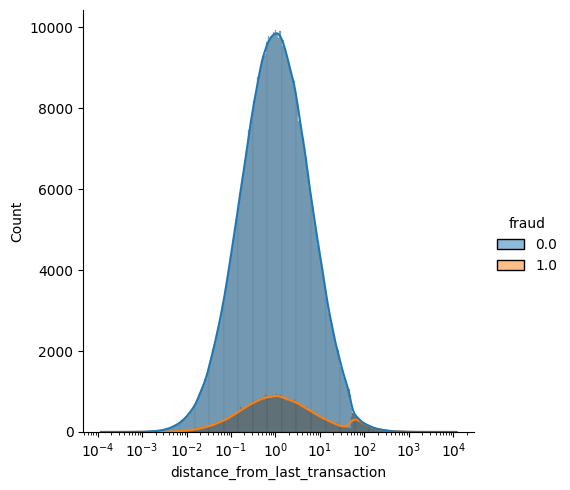

In [69]:
sns.displot(data=df, x='distance_from_home', hue='fraud', log_scale=True, kde=True)
sns.displot(data=df, x='distance_from_last_transaction', hue='fraud', log_scale=True, kde=True)
plt.show()



## Feature Engineering

In [70]:
ct = make_column_transformer(
    (StandardScaler(), num_ft)
)

df_scaled = pd.DataFrame(ct.fit_transform(df), columns=num_ft)
df_cat_feats = df[cat_ft]

df_concat = pd.concat([df_scaled, df_cat_feats], axis=1)
df_concat.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,0.477882,-0.182849,0.043491,1.0,1.0,0.0,0.0,0.0
1,-0.241607,-0.188094,-0.189300,1.0,0.0,0.0,0.0,0.0
2,-0.329369,-0.163733,-0.498812,1.0,0.0,0.0,1.0,0.0
3,-0.372854,0.021806,-0.522048,1.0,1.0,0.0,1.0,0.0
4,0.268572,-0.172968,0.142373,1.0,1.0,0.0,1.0,0.0


## For anomaly detection, we only need genuine (normal) class of the data for training samples

For anomaly detection, we only need genuine class of the data

In [71]:
X = df_concat.drop(["fraud"],axis=1)
y = df_concat["fraud"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=40)

y_train = y_train.astype(bool) # 0: False , 1: True (fraud)
y_test = y_test.astype(bool)

X_train_genuine = X_train[~y_train]
X_test_genuine = X_test[~y_test]

X_train_fraud = X_train[y_train]
X_test_fraud = X_test[y_test]

## Model Building - Autoencoder

## Architecture

In [89]:
CODE_DIM = 2 # bottleneck (input reduced to 2 features)
INPUT_SHAPE = X_train.shape[1] # nb of features

input_layer = Input(shape=(INPUT_SHAPE,))
x = Dense(64, activation='relu')(input_layer)
x = Dense(16, activation='relu')(x)
code = Dense(CODE_DIM, activation='relu')(x)
x = Dense(16, activation='relu')(code)
x = Dense(64, activation='relu')(x)
output_layer = Dense(INPUT_SHAPE, activation='relu')(x)

ae = Model(input_layer, output_layer, name='frauddetections')
ae.summary()

Model: "frauddetections"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,177 (12.41 KB)

 Trainable params: 3,177 (12.41 KB)

 Non-trainable params: 0 (0.00 B)

## model callbacks

In [90]:
model_name = "ae_anomaly.weights.h5"
checkpoint = ModelCheckpoint(model_name,
                            monitor="val_loss",
                            mode="min",
                            save_best_only = True,
                            save_weights_only=True,
                            verbose=1)
earlystopping = EarlyStopping(monitor='val_loss',
                              min_delta = 0,
                              patience = 5,
                              verbose = 1,
                              restore_best_weights=True)

callbacks = [checkpoint, earlystopping]

## Compilation

In [91]:
ae.compile(loss='mae', optimizer='adam')

## Training

In [92]:
history = ae.fit(X_train_genuine, X_train_genuine,
                          epochs=25, batch_size=64,
                          validation_data=(X_test, X_test),
                          callbacks=callbacks, shuffle=True)

Epoch 1/25
11402/11408 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3434
Epoch 1: val_loss improved from None to 0.36249, saving model to ae_anomaly.weights.h5

Epoch 1: finished saving model to ae_anomaly.weights.h5
11408/11408 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - loss: 0.3410 - val_loss: 0.3625
Epoch 2/25
11397/11408 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3195
Epoch 2: val_loss improved from 0.36249 to 0.33048, saving model to ae_anomaly.weights.h5

Epoch 2: finished saving model to ae_anomaly.weights.h5
11408/11408 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - loss: 0.3117 - val_loss: 0.3305
Epoch 3/25
11404/11408 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3053
Epoch 3: val_loss improved from 0.33048 to 0.22159, saving model to ae_anomaly.weights.h5

Epoch 3: finished saving model to ae_anomaly.weights.h5
11408/11408 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.2847 - val_loss: 0.2216
Epoch 4/25
11388/11408 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1983
Epoch 4: val_loss improved from 0.2215

## Result

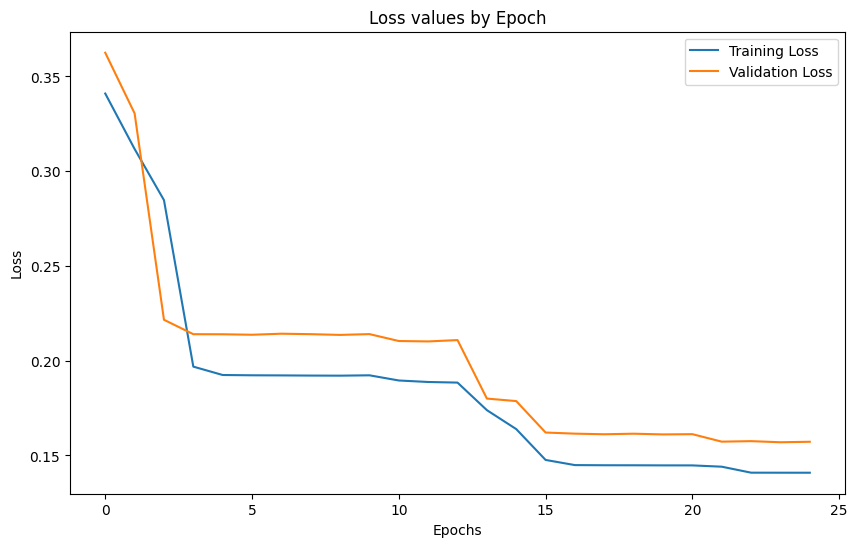

In [93]:
plt.figure(figsize=(10,6))
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title("Loss values by Epoch")
plt.show()

## Reconstruction
We will start by making a prediction on the test set which consists of both classes. After this, we can define a threshold and a metric, depending upon the need. The idea is simple:

    If the Reconstruction error is lower than the threshold, the sample is genuine
    If the Reconstruction error is higher than the threshold, the sample is fraud

This is because the model was trained with samples of genuine class, so anything outside of this threshold is considered an anomaly.

In [97]:
reconstructions = ae.predict(X_test, verbose=0)
reconstruction_error = mae(reconstructions, X_test)

Create Dataframe with reconstruction error and true labels(fraud or not)

In [103]:
recons_df = pd.DataFrame({ "error":reconstruction_error, "y_true":y_test})
recons_df.sort_values("error",ascending=False).head(20)

,error,y_true
596199,16.315710,False
567609,15.242013,False
65547,11.783459,False
289112,9.620386,False
531781,8.300477,False
29848,7.943114,True
404464,7.851887,True
956807,7.562474,True
101137,6.790014,False
321966,6.711240,True


## Finding the Ideal Threshold

Choosing the right threshold is crucial in anomaly detection with autoencoders because it determines the tradeoff between detecting anomalies and generating false positives (false alerts). The threshold determines the cutoff point for the reconstruction error, above which a data point is classified as anomalous. If the threshold is set too low, the autoencoder will classify many normal data points as anomalies, resulting in a high false alerts rate. On the other hand, if the threshold is set too high, the autoencoder may miss some true anomalies, resulting in a high false negative (missed anomaly) rate.

The metric we will choose for this problem is Recall, as we want to reduce False Negatives. Any Fraud transcation classified as Genuine may lead to unnoticed problems in the system, since there will never be anomaly detected. To find the right threshold value, several values will be tested to find the best combination of metrics. While our goal is to improve Recall, we will also keep track of the accuracy. The tested values will be percentiles of the reconstruction error values.

In [105]:
def thresholdTuning(df, iterations):

    thresh_df = {
        'threshold': [],
        'accuracy': [],
        'precision': [],
        'recall': []
    }

    for i in range(iterations):
        thresh_value = df['error'].quantile(i/iterations)
        preds = df['error'] > thresh_value
        cr = classification_report(df['y_true'], preds, output_dict=True)
        acc = cr['accuracy']
        prec = cr['macro avg']['precision']
        rc = cr['macro avg']['recall']

        thresh_df['threshold'].append(thresh_value)
        thresh_df['accuracy'].append(acc)
        thresh_df['precision'].append(prec)
        thresh_df['recall'].append(rc)

        print(f"Threshold: {thresh_value:.4f}\tAccuracy: {acc:.3f}\t\tPrecision: {prec:.3f}\tRecall Score: {rc:.3f}")

    return pd.DataFrame(thresh_df)

thresh_df = thresholdTuning(recons_df, 10)

Threshold: 0.0011	Accuracy: 0.087		Precision: 0.544	Recall Score: 0.500
Threshold: 0.0639	Accuracy: 0.178		Precision: 0.523	Recall Score: 0.526
Threshold: 0.0822	Accuracy: 0.272		Precision: 0.531	Recall Score: 0.562
Threshold: 0.0952	Accuracy: 0.366		Precision: 0.538	Recall Score: 0.599
Threshold: 0.1074	Accuracy: 0.461		Precision: 0.546	Recall Score: 0.637
Threshold: 0.1202	Accuracy: 0.557		Precision: 0.557	Recall Score: 0.678
Threshold: 0.1344	Accuracy: 0.654		Precision: 0.575	Recall Score: 0.725
Threshold: 0.1503	Accuracy: 0.750		Precision: 0.601	Recall Score: 0.767
Threshold: 0.1940	Accuracy: 0.832		Precision: 0.631	Recall Score: 0.763
Threshold: 0.2726	Accuracy: 0.890		Precision: 0.667	Recall Score: 0.688


In [106]:
threshold = thresh_df[thresh_df['recall'] == thresh_df['recall'].max()]['threshold'].values[0]
print(f"Threshold with Maximum Recall: {threshold:.6f}")

Threshold with Maximum Recall: 0.150329


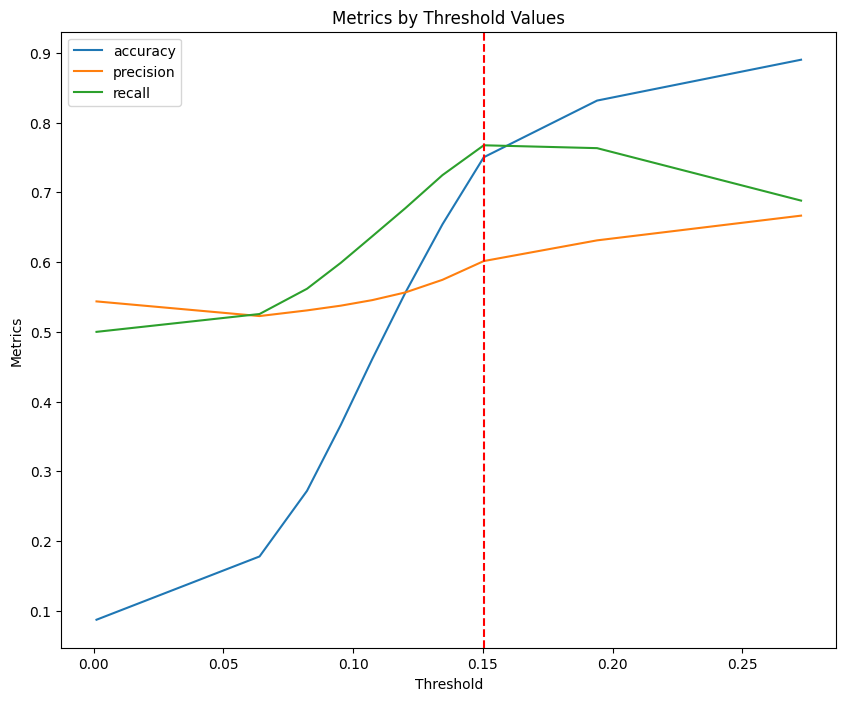

In [107]:

plt.figure(figsize=(10,8))
plt.plot(thresh_df['threshold'], thresh_df['accuracy'], label='accuracy')
plt.plot(thresh_df['threshold'], thresh_df['precision'], label='precision')
plt.plot(thresh_df['threshold'], thresh_df['recall'], label='recall')
plt.axvline(x=threshold, color='r', linestyle='dashed')
plt.xlabel('Threshold')
plt.ylabel('Metrics')
plt.title('Metrics by Threshold Values')
plt.legend()
plt.show()



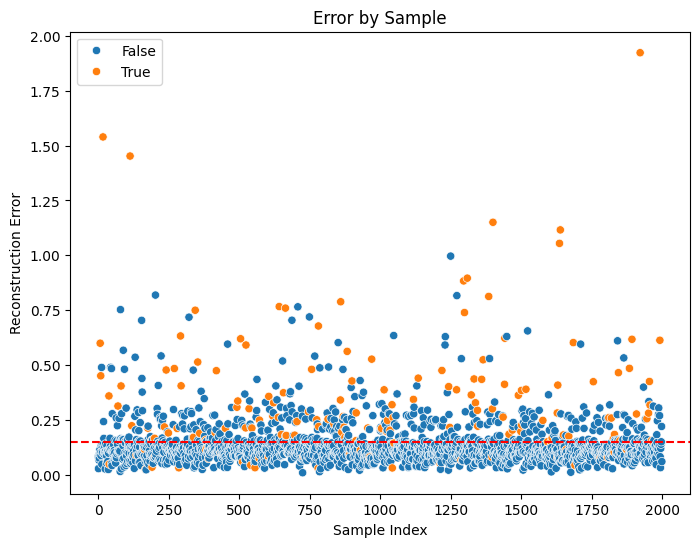

In [113]:
temp = recons_df.sample(frac=0.01, random_state=42).reset_index(drop=True)
plt.figure(figsize=(8,6))
sns.scatterplot(data=temp, x=temp.index, y='error', hue='y_true')
plt.axhline(y=threshold, color='r', linestyle='dashed')
plt.xlabel('Sample Index')
plt.ylabel('Reconstruction Error')
plt.title('Error by Sample')
plt.legend()
plt.show()

## Classification

In [114]:
recons_df['y_pred'] = recons_df['error'] > threshold
recons_df.head()

,error,y_true,y_pred
884729,0.115339,False,False
712573,0.060633,False,False
228524,0.279540,True,True
322732,0.091519,False,False
937308,0.149683,False,False


In [115]:
print(classification_report(recons_df['y_true'],recons_df['y_pred']))

              precision    recall  f1-score   support

       False       0.97      0.75      0.85    182538
        True       0.23      0.79      0.36     17462

    accuracy                           0.75    200000
   macro avg       0.60      0.77      0.60    200000
weighted avg       0.91      0.75      0.80    200000



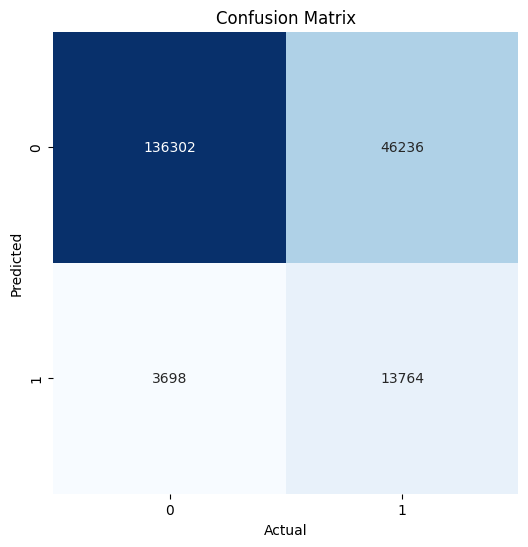

In [116]:


cm = confusion_matrix(recons_df['y_true'],recons_df['y_pred'])
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, cmap='Blues', cbar=False, fmt='.6g')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix')
plt.show()



## Results

In [117]:

print(f"Recall Score: {recall_score(recons_df['y_true'],recons_df['y_pred'])*100:.3f}%")
print(f"Accuracy Score: {accuracy_score(recons_df['y_true'],recons_df['y_pred'])*100:.3f}%")



Recall Score: 78.823%
Accuracy Score: 75.033%
